## Part One: Preparing the Data

Aylie Lapierre Nagler <br>
October 19, 2026

This data is sourced from UCF101 (Soomro et al., 2012), a public action-recognition dataset from the University of Central Florida's Center for Research in Computer Vision (https://www.crcv.ucf.edu/data/UCF101.php). It contains 13,320 labelled YouTube video clips across 101 human actions, grouped into 25 groups per action by source video. The purpose of this notebook is to isolate the videos pertaining to exercise for our eight classes (body-weight squats, lunges, push-ups, wall push-ups, pull-ups, handstand push-ups, jumping jacks and jump rope), split them into training, validation and test sets without letting any source video appear in more than one set, and convert each clip into 32 evenly spaced frames saved as NumPy arrays for feature extraction in the next notebook.

### Import Libraries

In [1]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import os

### Extract Data Relevant to Exercises

In [3]:
classes = ['BodyWeightSquats', 'Lunges', 'PushUps', 'WallPushups',
           'PullUps', 'HandstandPushups', 'JumpingJack', 'JumpRope']
data = '../DATA'

def get_paths(filename):
    """
    Function to get paths to data

    Parameter: name of the reference file w/ names of files containing data

    Output: 
        numpy array with paths
        numpy array with labels
    """
    paths, labels = [], []
    for line in open(data + '/ucfTrainTestlist/' + filename):
        path = line.split()[0]
        label = path.split('/')[0]
        if label in classes:
            paths.append(data + '/UCF-101/' + path)
            labels.append(classes.index(label))
                  # was '/videos/'
    
    return np.array(paths), np.array(labels)

In [4]:
# Run get_paths() function on lists of training and test data
train_paths, y_train = get_paths('trainlist01.txt')
test_paths, y_test = get_paths('testlist01.txt')

We need to split off a validation set containing all of the instances of a subject. This prevents data leakage.

The data is organized into groups, with each group containing the entirety of at least one subject's footage. As such, we will manually stratify the dataset using these groups before splitting. The file name format is '..._g##_...'. We will split on the '_g' and index for the numbers that follow.

The researchers put groups 1-7 in test, and groups 8-25 in training. We will split off groups 22-25 to isolate about 20% of the training data for validation.

In [5]:
# Split off validation data from training data
groups = np.array([int(p.split('_g')[1][:2]) for p in train_paths])
val = groups >= 22
train = groups < 22

val_paths, y_val = train_paths[val], y_train[val]
train_paths, y_train = train_paths[train], y_train[train]

total_len = len(train_paths) + len(val_paths) + len(test_paths)

print(f"Amt of Training Data: {len(train_paths)} ({(len(train_paths) / total_len * 100):.2f}%) \n"
         f"Amt of Validation Data: {len(val_paths)} ({(len(val_paths) / total_len * 100):.2f}%) \n"
         f"Amt of Testing Data: {len(test_paths)} ({(len(test_paths) / total_len * 100):.2f}%")

Amt of Training Data: 552 (57.14%) 
Amt of Validation Data: 151 (15.63%) 
Amt of Testing Data: 263 (27.23%


Next we will assess class imbalances:

In [6]:
for name, y in [('train', y_train), ('val', y_val), ('test', y_test)]:
      print(name, len(y), np.bincount(y, minlength=len(classes)))

train 552 [62 72 56 78 56 79 67 82]
val 151 [20 18 16 17 16 21 19 24]
test 263 [30 37 30 35 28 28 37 38]


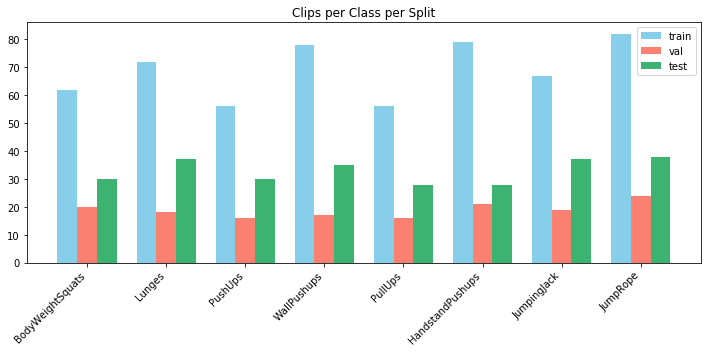

In [7]:
x = np.arange(len(classes))
bar_width = 0.25

plt.figure(figsize=(10,5))

plt.bar(x - bar_width, np.bincount(y_train), width=bar_width, label='train', color='skyblue')
plt.bar(x, np.bincount(y_val), width=bar_width, label='val', color='salmon')
plt.bar(x + bar_width, np.bincount(y_test), width=bar_width, label='test', color='mediumseagreen')

plt.title('Clips per Class per Split')
plt.xticks(x, classes, rotation=45, ha='right')

plt.legend()
plt.tight_layout()
plt.show()

**NEEDS OBSERVATIONS**

### Save

Save the splits so np.load() can be used going forward, teammates don't need to download full dataset (> 6 GB), and splits are preserved.

In [8]:
np.savez(data + '/splits.npz',
         train_paths=train_paths, y_train=y_train,
         val_paths=val_paths, y_val=y_val,
         test_paths=test_paths, y_test=y_test)

### Extract frames to .npy

Each clip will be saved in one array in the shape of (32, 224, 224, 3). 32 frames are sampled accross the whole clip. If an experiment requires 16 or 8 frames, the researcher can take every 2nd or 4th frame to achieve this. <br> <br>

The shape is as follows: (32 frames, 224 pixels height, 224 pixels width, 3 colour channels)

First we initialize a function to standardize file paths and naming for the frames:

**Before:** '../DATA/videos/PushUps/v_PushUps_g08_c01.avi' <br> 
**After:** '../DATA/frames/v_PushUps_g08_c01.npy'


In [9]:
def frame_file(path):
    return data  + '/frames/' + path.split('/')[-1].replace('.avi', '.npy')

In [10]:
def load_clip(path, n_frames=32, size=224):
    cap = cv2.VideoCapture(path)
    frames = []
    ok, frame = cap.read() # Read the first frame
    # Read every frame until the video ends
    while ok:
        frame = cv2.resize(frame, (size, size)) # Resize the frame to (224, 224, 3)
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)) # Reorder to RGB, which the pretrained CNNs expect
        ok, frame = cap.read() # Read the next frame
    cap.release() # Close video file
    # Get 32 evenly spaced frames
    idx = np.linspace(0, len(frames) - 1, n_frames).astype(int)
    return np.stack(frames)[idx] # Combine individual frame arrays into one array, keep the 32 chosen frames

In [11]:
splits = np.load(data + '/splits.npz')
all_paths = np.concatenate([splits['train_paths'], splits['val_paths'], splits['test_paths']])

In [12]:
from tqdm import tqdm

for path in tqdm(list(train_paths) + list(val_paths) + list(test_paths)):
    if not os.path.exists(frame_file(path)):
        np.save(frame_file(path), load_clip(path))

100%|██████████| 966/966 [00:00<00:00, 7682.41it/s]
